# A/B tests: counts and moments

A conversion experiment records one Bernoulli outcome per user. The likelihood for an arm's conversion
rate $p$ depends on those outcomes only through two numbers:

$$\prod_{i=1}^{n} p^{y_i}(1-p)^{1-y_i} = p^{k}(1-p)^{n-k}, \qquad T(y) = (n, k).$$

For a continuous outcome such as revenue per user under a Normal model, the count, mean and sum of squared
deviations $T(y) = (n, \bar y, SS)$ are sufficient for $(\mu, \sigma)$:

$$\sum_i \log \mathcal N(y_i \mid \mu,\sigma) = -\tfrac{n}{2}\log(2\pi\sigma^2) - \frac{SS + n(\bar y-\mu)^2}{2\sigma^2}.$$

This notebook first shows what the posterior is used for (a ship/no-ship decision that can be updated
daily from running counts), then fits each model on raw rows and on $T(y)$ and compares the posteriors and
run times.

Plotting convention for all notebooks: colour marks the category, a filled translucent histogram or band is
the raw-row fit, a solid line is the compressed fit, black dashed is an exact (conjugate) answer, and thin
grey is the true value. Intervals are 89%.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

rng = np.random.default_rng(101)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)
TIMINGS = []


def timed_fit(model, label, n_rows, case, kind, **kw):
    """Sample a model, record wall time and min bulk ESS per second, and return the InferenceData."""
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    TIMINGS.append({"case": case, "kind": kind, "model": label, "rows": int(n_rows),
                    "wall_s": round(secs, 2), "min_ess_per_s": round(ess / secs, 1)})
    return idata


def save_timings(name):
    Path("timings").mkdir(exist_ok=True)
    Path(f"timings/{name}.json").write_text(json.dumps(TIMINGS, indent=1))
    return pd.DataFrame(TIMINGS).drop(columns="case")

## Conversions

Two arms of 400,000 users each. Control converts at 4.0% and treatment at 4.08%, a 2% relative lift. Users
arrive over 14 days.

In [2]:
n_per_arm, n_days = 400_000, 14
true_p = np.array([0.040, 0.0408])
arm = np.repeat([0, 1], n_per_arm)
day = rng.integers(0, n_days, len(arm))
y = rng.binomial(1, true_p[arm])

counts = pd.DataFrame({"arm": arm, "y": y}).groupby("arm").y.agg(n="count", k="sum")
counts

,n,k
arm,,
0,400000,15797
1,400000,16365


## What the posterior is for

With a Beta(1, 1) prior the posterior for each arm is $\text{Beta}(1 + k, 1 + n - k)$, so no sampler is
needed. Two quantities support a decision:

- the probability that treatment is better, $P(p_T > p_C)$;
- the **expected loss** of shipping treatment, $E[\max(p_C - p_T, 0)]$: the conversion rate given up, on
  average, in the cases where treatment is worse. A common rule is to ship once the expected loss falls
  below a tolerance set in advance.

Because $(n, k)$ adds across days, both quantities can be recomputed each day from running totals.

In [3]:
daily = (pd.DataFrame({"arm": arm, "day": day, "y": y})
         .groupby(["day", "arm"]).y.agg(n="count", k="sum").unstack("arm"))
cum_n, cum_k = daily["n"].cumsum().values, daily["k"].cumsum().values      # (day, arm)


def beta_draws(n, k, size=20_000):
    return rng.beta(1 + k, 1 + n - k, size=(size,) + np.shape(n))


track = []
for d in range(n_days):
    draws = beta_draws(cum_n[d], cum_k[d])
    track.append({"day": d + 1, "users": cum_n[d].sum(),
                  "p_better": (draws[:, 1] > draws[:, 0]).mean(),
                  "exp_loss": np.maximum(draws[:, 0] - draws[:, 1], 0).mean()})
track = pd.DataFrame(track)

final = beta_draws(counts.n.values, counts.k.values)
rel_lift = final[:, 1] / final[:, 0] - 1

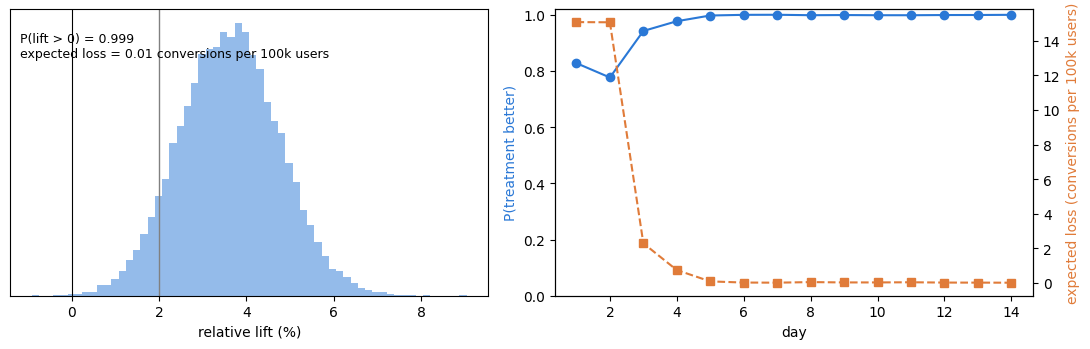

In [4]:
#| label: fig-ab-use
#| fig-cap: "Left: posterior of the relative lift in conversion rate after 14 days, from the conjugate Beta posterior on (n, k). Right: probability that treatment is better and expected loss of shipping it (conversions lost per 100,000 users), recomputed each day from running (n, k) totals."
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.hist(100 * rel_lift, bins=60, density=True, color="#2a78d6", alpha=0.5)
ax.axvline(0, color="k", lw=0.8)
ax.axvline(100 * (true_p[1] / true_p[0] - 1), color="grey", lw=1)
ax.set_xlabel("relative lift (%)")
ax.set_yticks([])
ax.text(0.02, 0.92, f"P(lift > 0) = {(rel_lift > 0).mean():.3f}\nexpected loss = "
        f"{1e5 * np.maximum(final[:, 0] - final[:, 1], 0).mean():.2f} conversions per 100k users",
        transform=ax.transAxes, va="top", fontsize=9)
ax = axes[1]
ax.plot(track.day, track.p_better, "o-", color="#2a78d6", label="P(treatment better)")
ax.set_ylim(0, 1.02)
ax.set_xlabel("day")
ax.set_ylabel("P(treatment better)", color="#2a78d6")
ax2 = ax.twinx()
ax2.plot(track.day, 1e5 * track.exp_loss, "s--", color="#e07b39", label="expected loss")
ax2.set_ylabel("expected loss (conversions per 100k users)", color="#e07b39")
plt.tight_layout()
plt.show()

## Raw rows vs counts

The same model fitted twice with NUTS: a Bernoulli likelihood over 800,000 rows and a Binomial
likelihood over two rows.

In [5]:
coords = {"arm": ["control", "treatment"]}

with pm.Model(coords=coords) as bern_full:
    p = pm.Beta("p", 1, 1, dims="arm")
    pm.Deterministic("lift", p[1] - p[0])
    pm.Bernoulli("y", p=p[arm], observed=y)

with pm.Model(coords=coords) as bern_suff:
    p = pm.Beta("p", 1, 1, dims="arm")
    pm.Deterministic("lift", p[1] - p[0])
    pm.Binomial("k", n=counts.n.values, p=p, observed=counts.k.values)

idata_bf = timed_fit(bern_full, "Bernoulli, raw rows", len(y), "Conversion test", "raw")
idata_bs = timed_fit(bern_suff, "Binomial, (n, k) per arm", len(counts), "Conversion test", "compressed")
exact_lift = final[:, 1] - final[:, 0]

NUTS[nutpie]: [p]
NUTS[nutpie]: [p]


## Revenue per user

200,000 users per arm, revenue with mean 10.0 vs 10.15 and standard deviation 6.

The compressed model uses two observed distributions instead of a `pm.Potential`. Under the Normal model,
$\bar y \sim \mathcal N(\mu, \sigma/\sqrt n)$ and $SS/\sigma^2 \sim \chi^2_{n-1}$, independently. The second is
$SS \sim \text{Gamma}\big((n-1)/2,\ \text{rate} = 1/(2\sigma^2)\big)$. The product of these two densities is
proportional in $(\mu, \sigma)$ to the full Normal likelihood, so the posterior is the same. Unlike a
`Potential`, observed variables keep a pointwise log-likelihood.

In [6]:
n_rev = 200_000
true_mu, true_sigma = np.array([10.0, 10.15]), 6.0
arm_r = np.repeat([0, 1], n_rev)
rev = rng.normal(true_mu[arm_r], true_sigma)

moments = (pd.DataFrame({"arm": arm_r, "rev": rev}).groupby("arm").rev
           .agg(n="count", ybar="mean", SS=lambda s: ((s - s.mean()) ** 2).sum()))
moments

,n,ybar,SS
arm,,,
0,200000,9.990989,7.200699e+06
1,200000,10.158680,7.178071e+06


In [7]:
with pm.Model(coords=coords) as norm_full:
    mu = pm.Normal("mu", 10, 5, dims="arm")
    sigma = pm.HalfNormal("sigma", 10)
    pm.Deterministic("delta", mu[1] - mu[0])
    pm.Normal("rev", mu[arm_r], sigma, observed=rev)

n_, ybar_, SS_ = (moments[c].values for c in ["n", "ybar", "SS"])
with pm.Model(coords=coords) as norm_suff:
    mu = pm.Normal("mu", 10, 5, dims="arm")
    sigma = pm.HalfNormal("sigma", 10)
    pm.Deterministic("delta", mu[1] - mu[0])
    pm.Normal("ybar", mu=mu, sigma=sigma / np.sqrt(n_), observed=ybar_)
    pm.Gamma("SS", alpha=(n_ - 1) / 2, beta=1 / (2 * sigma**2), observed=SS_)

idata_nf = timed_fit(norm_full, "Normal, raw rows", len(rev), "Normal outcome", "raw")
idata_ns = timed_fit(norm_suff, "Normal + Gamma on (n, ȳ, SS)", len(moments), "Normal outcome", "compressed")

NUTS[nutpie]: [mu, sigma]
NUTS[nutpie]: [mu, sigma]


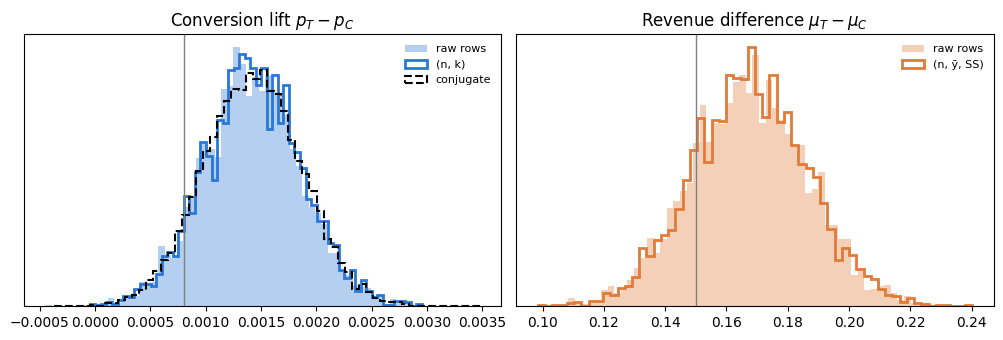

In [8]:
#| label: fig-ab-equiv
#| fig-cap: "Posterior for the treatment effect from raw rows (filled) and from the sufficient statistics (line). Left: absolute conversion lift, with the exact conjugate posterior dashed. Right: revenue difference. Grey lines mark the true values."
def draws(idata, var):
    return idata.posterior[var].values.ravel()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
ax = axes[0]
ax.hist(draws(idata_bf, "lift"), bins=60, density=True, alpha=0.35, color="#2a78d6", label="raw rows")
ax.hist(draws(idata_bs, "lift"), bins=60, density=True, histtype="step", lw=2, color="#2a78d6", label="(n, k)")
ax.hist(exact_lift, bins=60, density=True, histtype="step", lw=1.5, ls="--", color="k", label="conjugate")
ax.axvline(true_p[1] - true_p[0], color="grey", lw=1)
ax.set_title("Conversion lift $p_T - p_C$")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.hist(draws(idata_nf, "delta"), bins=60, density=True, alpha=0.35, color="#e07b39", label="raw rows")
ax.hist(draws(idata_ns, "delta"), bins=60, density=True, histtype="step", lw=2, color="#e07b39", label="(n, ȳ, SS)")
ax.axvline(true_mu[1] - true_mu[0], color="grey", lw=1)
ax.set_title(r"Revenue difference $\mu_T - \mu_C$")
ax.legend(frameon=False, fontsize=8)
for a in axes:
    a.set_yticks([])
plt.tight_layout()
plt.show()

In [9]:
#| label: tbl-ab-speed
#| tbl-cap: "Rows in the likelihood, wall time (compile + sample, 4 chains × 2,000 iterations) and minimum bulk ESS per second."
save_timings("01_ab_tests_counts_and_moments")

,kind,model,rows,wall_s,min_ess_per_s
0,raw,"Bernoulli, raw rows",800000,42.37,97.6
1,compressed,"Binomial, (n, k) per arm",2,0.56,6846.8
2,raw,"Normal, raw rows",400000,9.78,596.9
3,compressed,"Normal + Gamma on (n, ȳ, SS)",2,0.72,7790.0


## What compression gives up

The three numbers $(n, \bar y, SS)$ describe a Normal sample completely. They do not describe other data.
Below, a zero-inflated revenue sample (half the users spend nothing) and a Normal sample are constructed to
have identical $(n, \bar y, SS)$. A model fitted to the summaries cannot tell them apart.

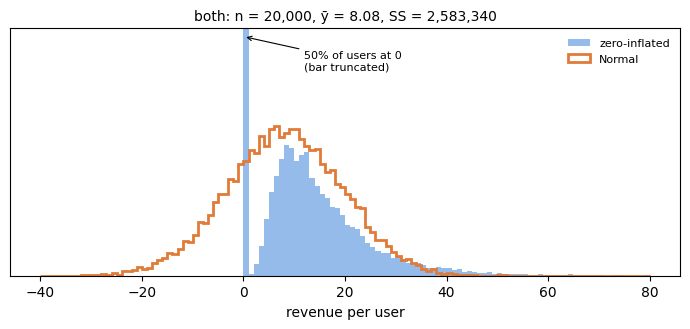

In [10]:
#| label: fig-ab-moments
#| fig-cap: "Two revenue samples with identical (n, ȳ, SS). The Normal model fitted to these three numbers gives the same posterior for both, although only one of them is Normal."
n_z = 20_000
zi = np.where(rng.random(n_z) < 0.5, 0.0, rng.lognormal(2.6, 0.6, n_z))
nrm = rng.normal(size=n_z)
nrm = (nrm - nrm.mean()) / nrm.std() * zi.std() + zi.mean()          # match mean and SS exactly
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(-40, 80, 121)
ax.hist(zi, bins=bins, density=True, alpha=0.5, color="#2a78d6", label="zero-inflated")
ax.hist(nrm, bins=bins, density=True, histtype="step", lw=2, color="#e07b39", label="Normal")
ax.set_ylim(0, 0.06)
ax.annotate("50% of users at 0\n(bar truncated)", xy=(0, 0.058), xytext=(12, 0.05), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.8))
ax.set_xlabel("revenue per user")
ax.set_yticks([])
ax.set_title(f"both: n = {n_z:,}, ȳ = {zi.mean():.2f}, SS = {((zi - zi.mean())**2).sum():,.0f}", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

- **Row-level checks.** Posterior predictive checks on individual users need the rows. Run them on the raw
  data, or a sample of it, before compressing.
- **Covariates.** $(n, k)$ is sufficient only within a cell of identical covariates. Each categorical
  covariate multiplies the number of cells. A continuous covariate usually gives each row its own cell.
- **Repeated users.** If a user can convert in several sessions, sessions from the same user are not
  interchangeable, and per-arm $(n, k)$ is no longer sufficient. The counts would need to be kept per user.

The summaries add across days, which is the property the sequential notebook uses.